# 02. Rainfall, neighbour rainfall, vegetation and ocean climate

**Goal:** turn four raw sources into county-month columns and attach them to the grid from notebook 01.

| source | raw file | columns we build |
|---|---|---|
| CHIRPS rainfall (WFP) | `data/raw/rainfall/ken-rainfall-subnat-full.csv` | `rain_mm`, `rain_max_dekad`, `rain_lag1`, `rain_lag2`, `rain_3mo_total`, `rain_pct_normal` |
| Neighbour rainfall | `data/reference/county_adjacency.csv` + the rainfall above | `neighbour_rain`, `neighbour_rain_lag1` |
| NDVI vegetation (WFP) | `data/raw/ndvi/ken-ndvi-subnat-full.csv` | `ndvi`, `ndvi_pct_normal` |
| ONI and DMI ocean indices (NOAA) | `data/raw/climate_indices/oni.csv`, `dmi_ersstv6.txt` | `oni`, `oni_lag1-3`, `dmi`, `dmi_lag1-3` |

**Inputs:** the raw files above and `data/interim/nb_grid.csv` (notebook 01). The pipeline files `data/interim/rainfall.csv`, `neighbour_rain.csv`, `ndvi.csv` and `climate.csv` are read only to cross-check our result.

**Output:** `data/interim/nb_rain_ndvi_climate.csv`, keyed by `pcode, year, month` (14,664 rows, 20 feature columns).

The reference is `src/data/02_rainfall.py` to `05_climate.py` and `common.py`.

In [1]:
# import the libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# load the grid made in notebook 01
grid = pd.read_csv("../../data/interim/nb_grid.csv", dtype={"pcode": str})
print(grid.shape)

(14664, 7)


**Observation:** The grid from notebook 01 has 14,664 rows (47 counties x 312 months) and 7 columns. The new columns will be added to it.

## 1. CHIRPS rainfall

### 1.1 What the raw file looks like

In [3]:
# load the raw rainfall file
rain_raw = pd.read_csv("../../data/raw/rainfall/ken-rainfall-subnat-full.csv", dtype={"PCODE": str}, parse_dates=["date"])
print(rain_raw.shape)
rain_raw[["date", "adm_level", "PCODE", "n_pixels", "rfh", "rfh_avg", "version"]].head()

(133488, 15)


,date,adm_level,PCODE,n_pixels,rfh,rfh_avg,version
0,1981-01-01,1,KE019,427.0,7.372365,15.759407,final
1,1981-01-11,1,KE019,427.0,4.325527,19.294770,final
2,1981-01-21,1,KE019,427.0,5.569087,16.265417,final
3,1981-02-01,1,KE019,427.0,5.882904,12.719282,final
4,1981-02-11,1,KE019,427.0,17.180328,18.768618,final


**Observation:** The raw rainfall file has 133,488 rows and 15 columns. The first rows are `adm_level` 1 rows for `KE019` (427 pixels) from January 1981: the first dekad has `rfh` = 7.37 mm against a long-term average `rfh_avg` of 15.76 mm. Each row is one area and one 10-day period, not one county and one month.

In [4]:
# date range, time step, version and units of the raw rainfall
print("first and last date:", rain_raw["date"].min().date(), rain_raw["date"].max().date())
print("day of month of each record (10-day steps):", sorted(rain_raw["date"].dt.day.unique().tolist()))
print("rows by adm_level:", rain_raw["adm_level"].value_counts().to_dict())
print("rows by version:", rain_raw["version"].value_counts().to_dict())
print("rfh (mm per 10 days) min, max:", rain_raw["rfh"].min(), round(rain_raw["rfh"].max(), 1))
print("missing rfh:", int(rain_raw["rfh"].isna().sum()))

first and last date: 1981-01-01 2026-10-01
day of month of each record (10-day steps): [1, 11, 21]
rows by adm_level: {2: 120304, 1: 13184}
rows by version: {'final': 133164, 'prelim': 324}
rfh (mm per 10 days) min, max: 0.0 476.3
missing rfh: 0


**Observation:** The records run from 1981-01-01 to 2026-10-01 in steps of 10 days (days 1, 11 and 21 of each month). There are 120,304 level-2 rows and 13,184 level-1 rows. 133,164 rows are `final` and 324 are `prelim` (the newest dekads). `rfh` goes from 0.0 to 476.3 mm per dekad with 0 missing values, so no gaps need filling.

`rfh` is the rainfall in **millimetres that fell in one 10-day period** (a dekad), as an average over the CHIRPS satellite pixels (0.05 degrees, about 5 km) inside an area. Every month has three dekads: days 1-10, 11-20 and 21 to the end of the month.

In [5]:
# check for gaps: number of dekads per year for one sub-county
one_area = rain_raw[rain_raw["PCODE"] == "KE042241"]
dekads_per_year = one_area.groupby(one_area["date"].dt.year).size()
print("full years with 36 dekads:", int((dekads_per_year == 36).sum()), "of", len(dekads_per_year))
print(dekads_per_year.tail(3).to_dict())

full years with 36 dekads: 45 of 46
{2024: 36, 2025: 36, 2026: 28}


**Observation:** For this sub-county, 45 of the 46 years have all 36 dekads (3 per month x 12). Only 2026 is incomplete (28 dekads, up to October), which is outside our grid anyway.

In [6]:
# keep only dates up to December 2025 (the grid ends there)
rain_raw = rain_raw[rain_raw["date"].dt.year <= 2025].copy()
print("last date kept:", rain_raw["date"].max().date())
print("rows left:", len(rain_raw))

last date kept: 2025-12-21
rows left: 131220


**Observation:** After keeping dates up to 2025 the last record is the dekad starting 21 December 2025, and 131,220 rows remain. The 2026 rows are removed because the grid ends in December 2025.

### 1.2 The province rows must go

The file has two kinds of rows. `adm_level` 2 rows are sub-county areas. `adm_level` 1 rows should be counties, but for 8 codes they are the **former provinces** (Rift Valley, Central, Eastern, Coast, ...) that reuse a county code. If we kept them, Turkana (`KE023`) would get the rainfall of the whole Rift Valley.

The evidence is the number of pixels. We compare, for each of the 8 codes, the pixels of the level-1 row with the pixels of the level-2 rows that start with the same 5 characters, and we divide the county's land area by the pixel count. A CHIRPS pixel covers roughly 31 km2 at Kenya's latitude.

In [7]:
# list the level-1 rows and compare their pixels with the level-2 rows of the same county
level1 = rain_raw[rain_raw["adm_level"] == 1].drop_duplicates("PCODE")[["PCODE", "n_pixels"]].rename(columns={"n_pixels": "pixels_level1"})
level2 = rain_raw[rain_raw["adm_level"] == 2].drop_duplicates("PCODE").copy()
level2["pcode"] = level2["PCODE"].str[:5]
level2_pixels = level2.groupby("pcode")["n_pixels"].sum().rename("pixels_level2")
level1 = level1.merge(level2_pixels, left_on="PCODE", right_index=True)
area = pd.read_csv("../../data/raw/earth_engine/worldcover_landcover_county_cod.csv", dtype={"pcode": str})[["pcode", "county", "area_km2"]]
level1 = level1.merge(area, left_on="PCODE", right_on="pcode")
level1["km2_per_pixel_level1"] = level1["area_km2"] / level1["pixels_level1"]
level1["km2_per_pixel_level2"] = level1["area_km2"] / level1["pixels_level2"]
level1[["PCODE", "county", "area_km2", "pixels_level1", "pixels_level2", "km2_per_pixel_level1", "km2_per_pixel_level2"]].round(1)

,PCODE,county,area_km2,pixels_level1,pixels_level2,km2_per_pixel_level1,km2_per_pixel_level2
0,KE019,Nyeri,3349.5,427.0,110.0,7.8,30.5
1,KE004,Tana River,39367.6,2683.0,1235.0,14.7,31.9
2,KE010,Marsabit,71424.7,4982.0,2304.0,14.3,31.0
3,KE047,Nairobi,710.7,26.0,26.0,27.3,27.3
4,KE008,Wajir,56922.1,4146.0,1849.0,13.7,30.8
5,KE043,Homa Bay,3232.7,414.0,109.0,7.8,29.7
6,KE023,Turkana,68111.1,5604.0,1886.0,12.2,36.1
7,KE037,Kakamega,3021.5,266.0,95.0,11.4,31.8


**Observation:** Apart from Nairobi, the level-1 row of each code has 2 to 4 times the pixels of the level-2 rows of the same county: `KE023` has 5,604 against 1,886 and `KE019` 427 against 110. With level-1 pixels the area per pixel would be 7.8 to 14.7 km2, which is impossible for a CHIRPS pixel (level-2 rows give 29.7 to 36.1 km2). Nairobi (`KE047`) has 26 pixels in both, so its level-1 row is just a copy and nothing is lost by dropping it.

In [8]:
# what area would the KE023 level-1 row cover, using the typical pixel size of the 8 counties?
km2_per_pixel = float(level1["km2_per_pixel_level2"].median())
pixels_ke023 = float(level1.loc[level1["PCODE"] == "KE023", "pixels_level1"].iloc[0])
print("typical pixel size from the level-2 rows (median of the 8 counties):", round(km2_per_pixel, 1), "km2")
print("area covered by the KE023 level-1 row:", round(pixels_ke023 * km2_per_pixel), "km2")
print("land area of Turkana county:", round(float(level1.loc[level1["PCODE"] == "KE023", "area_km2"].iloc[0])), "km2")

typical pixel size from the level-2 rows (median of the 8 counties): 30.9 km2
area covered by the KE023 level-1 row: 173123 km2
land area of Turkana county: 68111 km2


**Observation:** At the typical 30.9 km2 per pixel, the `KE023` level-1 row covers about 173,123 km2, which is 2.5 times the land area of Turkana (68,111 km2). It is the Rift Valley province, not the county, so it must not be used as Turkana's rainfall. This is why only level-2 rows are kept.

So we drop every `adm_level` 1 row and build all 47 counties from the `adm_level` 2 rows only. The county code is the first 5 characters of the sub-county code (`KE042241` belongs to `KE042`, Kisumu).

In [9]:
# keep only the level-2 rows and make the county code from the first 5 characters
rain = rain_raw[rain_raw["adm_level"] == 2].copy()
rain["pcode"] = rain["PCODE"].str[:5]
areas_per_county = rain.groupby("pcode")["PCODE"].nunique()
print("level-2 rows:", len(rain), "| level-2 areas:", rain["PCODE"].nunique(), "| counties:", rain["pcode"].nunique())
print("counties with one area:", int((areas_per_county == 1).sum()), "| with several areas:", int((areas_per_county > 1).sum()))

level-2 rows:

 118260 | level-2 areas: 73 | counties: 47
counties with one area: 26 | with several areas: 21


**Observation:** After dropping level 1 there are 118,260 level-2 rows from 73 areas that map to all 47 counties. 26 counties have a single area, but 21 counties have several areas and need a weighted mean.

### 1.3 One value per county per dekad

Counties with several sub-county areas need one number. A plain average would treat a tiny area like a huge one, so we use the **mean weighted by `n_pixels`** (how many satellite pixels each area has). Worked example: Kisumu has two areas, `KE042241` (23 pixels) and `KE042243` (46 pixels), for the dekad starting 1 April 2024.

In [10]:
# show the two Kisumu areas for one dekad and compute the weighted mean by hand
example = rain[(rain["pcode"] == "KE042") & (rain["date"] == "2024-04-01")][["PCODE", "n_pixels", "rfh"]]
print(example.to_string(index=False))
weighted = (example["rfh"] * example["n_pixels"]).sum() / example["n_pixels"].sum()
print("plain average :", round(example["rfh"].mean(), 3), "mm")
print("weighted mean :", round(weighted, 3), "mm")

   PCODE  n_pixels       rfh
KE042241      23.0 119.82609
KE042243      46.0  97.21739
plain average : 108.522 mm
weighted mean : 104.754 mm


**Observation:** The two Kisumu areas had 119.83 mm (23 pixels) and 97.22 mm (46 pixels). The plain average is 108.522 mm and the pixel-weighted mean is 104.754 mm. The area with twice the pixels gets twice the weight, which moves the county value down by about 3.8 mm towards it.

In [11]:
# weighted mean of rfh for every county and dekad
rain["rfh_x_pixels"] = rain["rfh"] * rain["n_pixels"]
dekad = rain.groupby(["pcode", "date"], as_index=False).agg(rfh_x_pixels=("rfh_x_pixels", "sum"), n_pixels=("n_pixels", "sum"))
dekad["rfh"] = dekad["rfh_x_pixels"] / dekad["n_pixels"]
print(dekad.shape)
dekad.head(3)

(76140, 5)


,pcode,date,rfh_x_pixels,n_pixels,rfh
0,KE001,1981-01-01,194.0,10.0,19.4
1,KE001,1981-01-11,41.0,10.0,4.1
2,KE001,1981-01-21,85.0,10.0,8.5


**Observation:** This gives 76,140 rows (47 counties x 1,620 dekads), one per county and dekad. Mombasa (`KE001`) has one area of 10 pixels, so its weighted value equals the area value: 19.4, 4.1 and 8.5 mm in January 1981.

In [12]:
# check: every county has the same dekads and no missing values
print("dekads per county (min, max):", dekad.groupby("pcode").size().min(), dekad.groupby("pcode").size().max())
print("counties:", dekad["pcode"].nunique())
print("missing rfh:", int(dekad["rfh"].isna().sum()))
print("first and last dekad:", dekad["date"].min().date(), dekad["date"].max().date())

dekads per county (min, max):

 1620 1620
counties: 47
missing rfh: 0
first and last dekad: 1981-01-01 2025-12-21


**Observation:** Every county has exactly 1,620 dekads (45 years x 36), from 1981-01-01 to 2025-12-21, for all 47 counties, and there are no missing values. The series are complete and aligned.

### 1.4 From dekads to months

A month's rainfall is the **sum** of its three dekads (each is millimetres that fell in 10 days). We also keep the largest dekad, because a single heavy dekad can cause a flood even when the month total looks ordinary. We assert that every county-month has exactly 3 dekads, otherwise a sum would be silently too small.

In [13]:
# add year and month and sum the three dekads of each month
dekad["year"] = dekad["date"].dt.year
dekad["month"] = dekad["date"].dt.month
monthly = dekad.groupby(["pcode", "year", "month"]).agg(rain_mm=("rfh", "sum"), rain_max_dekad=("rfh", "max"), n_dekads=("rfh", "size")).reset_index()
print("county-months:", len(monthly), "= 47 counties x", len(monthly) // 47, "months")
print("county-months with exactly 3 dekads:", int((monthly["n_dekads"] == 3).sum()), "of", len(monthly))
assert (monthly["n_dekads"] == 3).all()
monthly.head(3)

county-months: 25380 = 47 counties x 540 months
county-months with exactly 3 dekads: 25380 of 25380


,pcode,year,month,rain_mm,rain_max_dekad,n_dekads
0,KE001,1981,1,32.0,19.4,3
1,KE001,1981,2,7.2,5.1,3
2,KE001,1981,3,166.4,110.0,3


**Observation:** There are 25,380 county-months (47 counties x 540 months), and all of them have exactly 3 dekads, so no monthly sum is short. Mombasa in January 1981 received 32.0 mm in total, with its wettest dekad at 19.4 mm (`rain_max_dekad`).

### 1.5 Lags and the 3-month total

A model that predicts next month's flood can use what happened in the previous months: `rain_lag1` (one month earlier), `rain_lag2` (two months earlier) and `rain_3mo_total` (this month plus the two before). We compute them on the **full 1981-2025 series** first and only trim to 2000 afterwards, otherwise the first months of 2000 would have no lags.

In [14]:
# sort each county in time order and check the months are consecutive
monthly = monthly.sort_values(["pcode", "year", "month"]).reset_index(drop=True)
monthly["t"] = monthly["year"] * 12 + monthly["month"]
steps = monthly.groupby("pcode")["t"].diff().dropna()
print("every step is exactly 1 month:", bool((steps == 1).all()))

every step is exactly 1 month: True


**Observation:** Every step between consecutive months of a county is exactly 1 month, so shifting a column down by 1 or 2 rows really means 1 or 2 months earlier.

In [15]:
# add the two lags and the 3-month total
monthly["rain_lag1"] = monthly.groupby("pcode")["rain_mm"].shift(1)
monthly["rain_lag2"] = monthly.groupby("pcode")["rain_mm"].shift(2)
monthly["rain_3mo_total"] = monthly["rain_mm"] + monthly["rain_lag1"] + monthly["rain_lag2"]
monthly[(monthly["pcode"] == "KE042") & (monthly["year"] == 2024) & (monthly["month"].isin([2, 3, 4]))][["year", "month", "rain_mm", "rain_lag1", "rain_lag2", "rain_3mo_total"]].round(2)

,year,month,rain_mm,rain_lag1,rain_lag2,rain_3mo_total
22657,2024,2,161.19,167.45,125.14,453.78
22658,2024,3,168.32,161.19,167.45,496.96
22659,2024,4,273.07,168.32,161.19,602.58


**Observation:** For Kisumu, April 2024: `rain_mm` 273.07, `rain_lag1` 168.32 (March), `rain_lag2` 161.19 (February), and `rain_3mo_total` 602.58, which is 273.07 + 168.32 + 161.19. The lags line up with the earlier months in the rows above.

### 1.6 Rainfall relative to normal

Counties differ a lot in how much it normally rains (Mandera about 31 mm per month, Kisii about 156 mm), so 100 mm means very different things. `rain_pct_normal` divides a month's rain by the **average rain of the same county in the same calendar month over 2000-2019**. A value of 1.0 is normal and 1.25 is 125% of normal. We use only 2000-2019 (the training years) so that the test years do not leak into the definition of normal.

In [16]:
# average rain of each county and calendar month over 2000-2019
baseline = monthly[monthly["year"].between(2000, 2019)]
normal = baseline.groupby(["pcode", "month"])["rain_mm"].mean().rename("normal_mm").reset_index()
print("normals:", len(normal), "= 47 counties x 12 months")
print("smallest and largest normal (mm):", round(normal["normal_mm"].min(), 1), round(normal["normal_mm"].max(), 1))
print("normals equal to 0:", int((normal["normal_mm"] == 0).sum()))

normals: 564 = 47 counties x 12 months
smallest and largest normal (mm): 1.3 325.9
normals equal to 0: 0


**Observation:** There are 564 normals (47 counties x 12 months), from 1.3 mm for the driest county-month to 325.9 mm for the wettest. None is 0, so dividing by the normal never fails.

In [17]:
# divide each month's rain by its normal
monthly = monthly.merge(normal, on=["pcode", "month"], how="left")
monthly["rain_pct_normal"] = monthly["rain_mm"] / monthly["normal_mm"]
monthly = monthly.sort_values(["pcode", "year", "month"]).reset_index(drop=True)
kisumu = monthly[(monthly["pcode"] == "KE042") & (monthly["year"] == 2024) & (monthly["month"] == 4)]
print("Kisumu April 2024: rain", round(float(kisumu["rain_mm"].iloc[0]), 3), "mm; normal April", round(float(kisumu["normal_mm"].iloc[0]), 3), "mm")
print("rain_pct_normal =", round(float(kisumu["rain_pct_normal"].iloc[0]), 3))

Kisumu April 2024: rain

 273.072 mm; normal April 220.904 mm
rain_pct_normal = 1.236


**Observation:** Kisumu's April normal is 220.904 mm and April 2024 had 273.072 mm, so `rain_pct_normal` = 1.236. April 2024 was 124% of normal, just under the 1.25 limit used later for 'heavy rain'.

In [18]:
# trim to 2000-2025 and keep the rainfall columns
rain_cols = ["rain_mm", "rain_max_dekad", "rain_lag1", "rain_lag2", "rain_3mo_total", "rain_pct_normal"]
rain_features = monthly[monthly["year"] >= 2000][["pcode", "year", "month"] + rain_cols].reset_index(drop=True)
print(rain_features.shape)
print("missing values per column:", rain_features[rain_cols].isna().sum().sum())

(14664, 9)
missing values per column: 0


**Observation:** After trimming to 2000-2025 the table has 14,664 rows and 9 columns, with 0 missing values. Even January 2000 has its lags, which come from late 1999 because we kept the years before 2000 until this step.

### Sanity checks on the rainfall columns

In [19]:
# check 1: shape, keys and counties
print("rows:", len(rain_features), "| duplicate keys:", int(rain_features.duplicated(["pcode", "year", "month"]).sum()))
print("counties:", rain_features["pcode"].nunique())
print("years:", rain_features["year"].min(), "to", rain_features["year"].max())

rows: 14664 | duplicate keys: 0
counties: 47
years: 2000 to 2025


**Observation:** The rainfall table has 14,664 rows, 0 duplicate keys, 47 counties and years 2000 to 2025, the same as the grid.

In [20]:
# check 2: value ranges
print(rain_features[rain_cols].describe().loc[["min", "50%", "max"]].round(2))
print("share of months above 125% of normal:", round(float((rain_features["rain_pct_normal"] > 1.25).mean()), 3))

     rain_mm  rain_max_dekad  rain_lag1  rain_lag2  rain_3mo_total  \
min     0.61            0.27       0.61       0.61            2.73   
50%    71.47           36.50      71.38      71.80          250.23   
max   853.24          427.57     853.24     853.24         1340.63   

     rain_pct_normal  
min             0.12  
50%             0.93  
max             6.18  
share of months above 125% of normal: 0.261


**Observation:** `rain_mm` goes from 0.61 to 853.24 mm (median 71.47); the wettest dekad was 427.57 mm and the largest 3-month total 1,340.63 mm. `rain_pct_normal` goes from 0.12 to 6.18 with a median of 0.93, and 26.1% of all county-months are above 1.25. So a month with 25% extra rain is common (about 1 in 4), not a rare event.

In [21]:
# check 3: compare with the pipeline's data/interim/rainfall.csv
pipe_rain = pd.read_csv("../../data/interim/rainfall.csv", dtype={"pcode": str})
both = rain_features.merge(pipe_rain, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
print("rows matched:", len(both), "of", len(rain_features))
for c in rain_cols:
    print(c, "largest difference:", float((both[c] - both[c + "_pipe"]).abs().max()))

rows matched: 14664 of 14664
rain_mm largest difference: 0.0
rain_max_dekad largest difference: 0.0
rain_lag1 largest difference: 0.0
rain_lag2 largest difference: 0.0
rain_3mo_total largest difference: 0.0
rain_pct_normal largest difference: 0.0


**Observation:** All 14,664 rows match the pipeline's `rainfall.csv`, and the largest difference is 0.0 for all six columns. Our plain-pandas rebuild gives exactly the same numbers.

{1: 42.2, 2: 37.7, 3: 98.3, 4: 191.3, 5: 145.0, 6: 68.5, 7: 64.3, 8: 75.3, 9: 67.2, 10: 105.1, 11: 143.9, 12: 86.0}


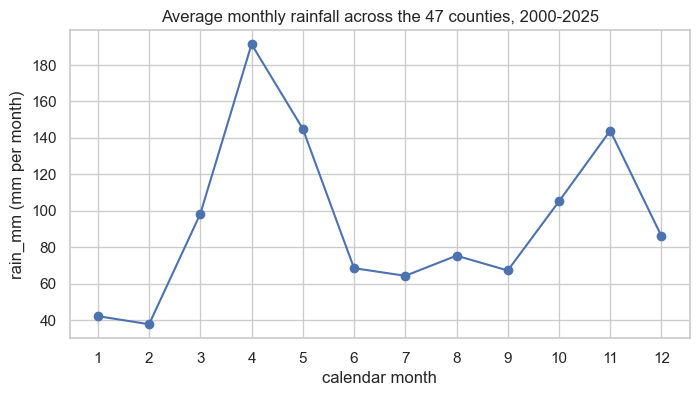

In [22]:
# average monthly rainfall by calendar month, all counties, 2000-2025
by_month = rain_features.groupby("month")["rain_mm"].mean()
print(by_month.round(1).to_dict())
plt.figure(figsize=(8, 4))
plt.plot(by_month.index, by_month.values, marker="o")
plt.xticks(range(1, 13))
plt.title("Average monthly rainfall across the 47 counties, 2000-2025")
plt.xlabel("calendar month")
plt.ylabel("rain_mm (mm per month)")
plt.show()

**Observation:** The long rains peak in April (191.3 mm) and May (145.0 mm), and the short rains in November (143.9 mm) and October (105.1 mm). The driest months are February (37.7 mm) and January (42.2 mm). Any flood model needs to know the month, since rain amounts differ by a factor of 5 between months.

### 1.7 Known limitation: some sub-counties sit under the wrong county

The WFP file has only 73 level-2 areas for 47 counties, and in two places the areas are filed under the neighbouring county: Kiambu / Murang'a and Kericho / Bomet. We can see it from the pixel counts: a county's pixels times about 31 km2 should be close to its land area.

In [23]:
# pixels per county compared with county land area, all 47 counties
pix = rain.drop_duplicates("PCODE").groupby("pcode")["n_pixels"].sum().rename("pixels").reset_index()
pix = pix.merge(area, on="pcode")
pix["km2_per_pixel"] = pix["area_km2"] / pix["pixels"]
typical = pix["km2_per_pixel"].median()
pix["area_covered_pct"] = 100 * (pix["pixels"] * typical) / pix["area_km2"]
print("typical km2 per pixel (median of 47 counties):", round(typical, 1))
pix[pix["county"].isin(["Kiambu", "Murang'a", "Kericho", "Bomet"])][["county", "pixels", "area_km2", "km2_per_pixel", "area_covered_pct"]].round(1)

typical km2 per pixel (median of 47 counties): 30.9


,county,pixels,area_km2,km2_per_pixel,area_covered_pct
20,Murang'a,119.0,2536.8,21.3,144.8
21,Kiambu,42.0,2554.4,60.8,50.7
34,Kericho,67.0,2524.5,37.7,81.9
35,Bomet,95.0,2449.2,25.8,119.7


**Observation:** Kiambu has 42 pixels for 2,554 km2 (60.8 km2 per pixel, against a typical 30.9), so its pixels cover only 50.7% of its area. Murang'a has 119 pixels for 2,537 km2 (21.3 km2 per pixel) and covers 144.8%. Kericho covers 81.9% and Bomet 119.7%. The 'missing' pixels of one county of a pair are counted in the other.

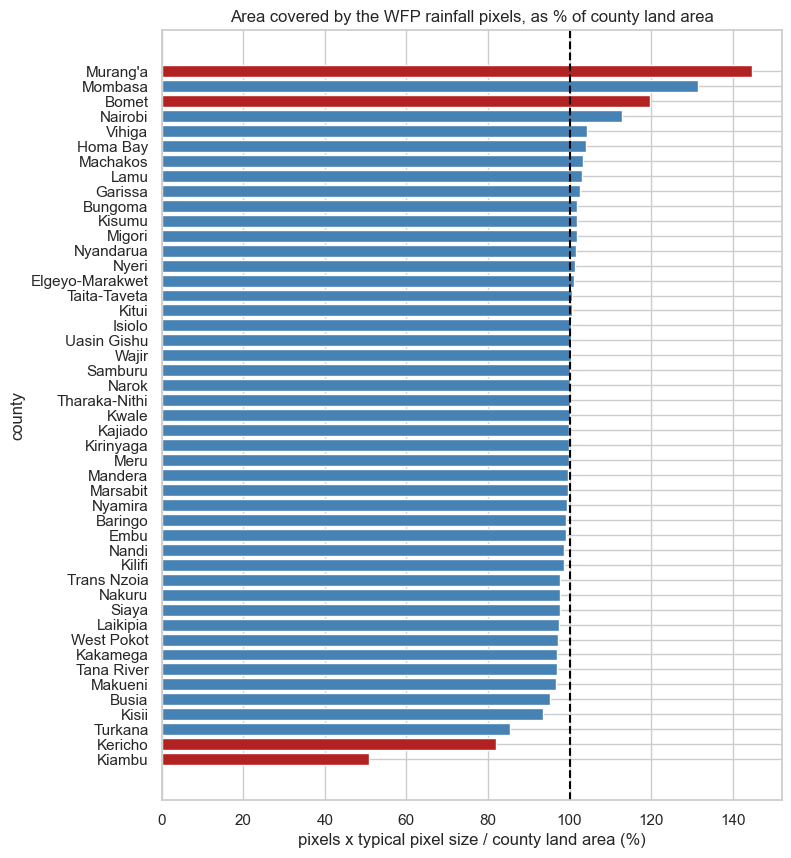

In [24]:
# plot the area covered by the rainfall pixels for every county
pix_sorted = pix.sort_values("area_covered_pct")
plt.figure(figsize=(8, 10))
colors = ["firebrick" if c in ["Kiambu", "Murang'a", "Kericho", "Bomet"] else "steelblue" for c in pix_sorted["county"]]
plt.barh(pix_sorted["county"], pix_sorted["area_covered_pct"], color=colors)
plt.axvline(100, color="black", linestyle="--")
plt.title("Area covered by the WFP rainfall pixels, as % of county land area")
plt.xlabel("pixels x typical pixel size / county land area (%)")
plt.ylabel("county")
plt.show()

**Observation:** The four counties in the Kiambu-Murang'a and Kericho-Bomet pairs are the clear outliers. Mombasa (about 131%) and Nairobi (about 113%) also look high, but they are small counties with only 10 and 26 pixels, so one pixel more or less moves the percentage a lot; that is rounding, not mis-filing. Turkana is at about 85%. We keep this as a known limitation.

**What this means.** The pixels exist but are filed under the wrong county of each pair. Kiambu's rainfall covers only about half of its area, while Murang'a's covers about 145% of its own, and Kericho and Bomet are off by about -18% and +20%. The pipeline cannot repair it because WFP supplies only 73 sub-county areas (the official map has 290). We keep the data as it is and report it as a limitation. It also affects `neighbour_rain` for the 16 counties that border these four, in total 20 counties.

## 2. Neighbour rainfall

`neighbour_rain` is the average rainfall of the counties that touch this county, in the same month. It tells the model whether the surrounding area is wet (water flows downstream across county borders). Each neighbour has the same weight. We use the full 1981-2025 monthly rainfall from section 1 so that the lag of January 2000 exists.

In [25]:
# load the adjacency pairs
adj = pd.read_csv("../../data/reference/county_adjacency.csv", dtype={"pcode": str, "neighbour_pcode": str})
print(adj.shape, "| counties:", adj["pcode"].nunique())

(244, 3) | counties: 47


**Observation:** The adjacency file has 244 directed pairs covering all 47 counties.

In [26]:
# attach the rainfall of each neighbour to every pair
neighbour_rain_raw = monthly[["pcode", "year", "month", "rain_mm"]].rename(columns={"pcode": "neighbour_pcode", "rain_mm": "neighbour_mm"})
pairs = adj[["pcode", "neighbour_pcode"]].merge(neighbour_rain_raw, on="neighbour_pcode")
print(pairs.shape, "= 244 pairs x", len(pairs) // 244, "months")

(131760, 5) = 244 pairs x 540 months


**Observation:** Pairing every neighbour with its monthly rainfall gives 131,760 rows (244 pairs x 540 months).

In [27]:
# average over the neighbours of each county and month
neighbour = pairs.groupby(["pcode", "year", "month"], as_index=False)["neighbour_mm"].mean().rename(columns={"neighbour_mm": "neighbour_rain"})
neighbour = neighbour.sort_values(["pcode", "year", "month"]).reset_index(drop=True)
neighbour["neighbour_rain_lag1"] = neighbour.groupby("pcode")["neighbour_rain"].shift(1)
neighbour = neighbour[neighbour["year"] >= 2000].reset_index(drop=True)
print(neighbour.shape, "| missing:", int(neighbour.isna().sum().sum()))

(14664, 5) | missing: 0


**Observation:** Averaging over the neighbours gives one value per county and month: 14,664 rows after trimming to 2000, with 0 missing values.

In [28]:
# worked example: Kisumu in April 2024
names = grid[["pcode", "county"]].drop_duplicates()
kis_neighbours = adj[adj["pcode"] == "KE042"].merge(names, left_on="neighbour_pcode", right_on="pcode", suffixes=("", "_n"))
kis_rain = pairs[(pairs["pcode"] == "KE042") & (pairs["year"] == 2024) & (pairs["month"] == 4)].merge(names, left_on="neighbour_pcode", right_on="pcode", suffixes=("", "_n"))
print(kis_rain[["county", "neighbour_mm"]].round(2).to_string(index=False))
print("mean of the 5 neighbours:", round(float(kis_rain["neighbour_mm"].mean()), 3))
print("neighbour_rain in the table:", round(float(neighbour[(neighbour["pcode"] == "KE042") & (neighbour["year"] == 2024) & (neighbour["month"] == 4)]["neighbour_rain"].iloc[0]), 3))

  county  neighbour_mm
Homa Bay        253.63
 Kericho        246.91
   Siaya        315.33
  Vihiga        299.11
   Nandi        232.23
mean of the 5 neighbours: 269.441
neighbour_rain in the table: 269.441


**Observation:** Kisumu's five neighbours had 253.63 (Homa Bay), 246.91 (Kericho), 315.33 (Siaya), 299.11 (Vihiga) and 232.23 mm (Nandi) in April 2024. The mean is 269.441 mm and it equals `neighbour_rain` in our table. Kisumu itself had 273.07 mm, so the whole region was wet.

In [29]:
# check against the pipeline's data/interim/neighbour_rain.csv
pipe_nb = pd.read_csv("../../data/interim/neighbour_rain.csv", dtype={"pcode": str})
both = neighbour.merge(pipe_nb, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
print("rows matched:", len(both), "of", len(neighbour))
print("largest difference neighbour_rain:", float((both["neighbour_rain"] - both["neighbour_rain_pipe"]).abs().max()))
print("largest difference neighbour_rain_lag1:", float((both["neighbour_rain_lag1"] - both["neighbour_rain_lag1_pipe"]).abs().max()))

rows matched: 14664 of 14664
largest difference neighbour_rain: 1.1368683772161603e-13
largest difference neighbour_rain_lag1: 1.1368683772161603e-13


**Observation:** All 14,664 rows match the pipeline's `neighbour_rain.csv`. The largest difference is 1.1e-13 mm, which is floating-point rounding from adding in a different order.

## 3. NDVI (vegetation greenness)

NDVI measures how green the vegetation is, from satellite images. It goes from 0 (bare) towards 1 (dense green). Very green land has taken up water earlier, and a sudden greening shows that it rained. We use the same rules as rainfall: drop the province rows, make the county code from the first 5 characters, and take the n_pixels-weighted mean.

In [30]:
# load the raw NDVI file
ndvi_raw = pd.read_csv("../../data/raw/ndvi/ken-ndvi-subnat-full.csv", dtype={"PCODE": str}, parse_dates=["date"])
print(ndvi_raw.shape)
print("first and last date:", ndvi_raw["date"].min().date(), ndvi_raw["date"].max().date())
print("rows by adm_level:", ndvi_raw["adm_level"].value_counts().to_dict())
print("vim range (NDVI per dekad):", round(ndvi_raw["vim"].min(), 3), round(ndvi_raw["vim"].max(), 3))
print("missing vim:", int(ndvi_raw["vim"].isna().sum()))
ndvi_raw[["date", "adm_level", "PCODE", "n_pixels", "vim", "vim_avg"]].head(3)

(70713, 8)
first and last date: 2002-07-01 2026-09-21
rows by adm_level: {2: 63729, 1: 6984}
vim range (NDVI per dekad): 0.073 0.841
missing vim: 0


,date,adm_level,PCODE,n_pixels,vim,vim_avg
0,2002-07-01,1,KE019,427.0,0.668536,0.684022
1,2002-07-11,1,KE019,427.0,0.658954,0.668657
2,2002-07-21,1,KE019,427.0,0.647139,0.657200


**Observation:** The raw NDVI file has 70,713 rows from 2002-07-01 to 2026-09-21: 63,729 level-2 rows and 6,984 level-1 rows. `vim` goes from 0.073 to 0.841 (inside the 0 to 1 range of NDVI) with 0 missing values. The first rows are `KE019` level-1, with `vim` 0.669 against a long-term `vim_avg` of 0.684.

In [31]:
# keep dates up to 2025 and level-2 rows only, then weight by pixels
ndvi_raw = ndvi_raw[ndvi_raw["date"].dt.year <= 2025]
ndvi = ndvi_raw[ndvi_raw["adm_level"] == 2].copy()
ndvi["pcode"] = ndvi["PCODE"].str[:5]
ndvi["vim_x_pixels"] = ndvi["vim"] * ndvi["n_pixels"]
ndvi_dekad = ndvi.groupby(["pcode", "date"], as_index=False).agg(vim_x_pixels=("vim_x_pixels", "sum"), n_pixels=("n_pixels", "sum"))
ndvi_dekad["vim"] = ndvi_dekad["vim_x_pixels"] / ndvi_dekad["n_pixels"]
print("level-1 rows dropped:", int((ndvi_raw["adm_level"] == 1).sum()))
print("counties:", ndvi_dekad["pcode"].nunique(), "| dekads per county:", ndvi_dekad.groupby("pcode").size().min())

level-1 rows dropped:

 6768
counties: 47 | dekads per county: 846


**Observation:** After the 2025 cut-off and dropping level 1 (6,768 level-1 rows removed), all 47 counties have 846 dekads (282 months x 3, July 2002 to December 2025).

**Mean, not sum.** NDVI is an index, not an amount. Adding three dekads would make a value of up to 3 that no longer means 'how green'. So the monthly NDVI is the **mean** of the 3 dekads (rainfall is a quantity of water, so it is summed).

In [32]:
# monthly NDVI as the mean of the three dekads, with a check of 3 dekads per month
ndvi_dekad["year"] = ndvi_dekad["date"].dt.year
ndvi_dekad["month"] = ndvi_dekad["date"].dt.month
ndvi_month = ndvi_dekad.groupby(["pcode", "year", "month"]).agg(ndvi=("vim", "mean"), n_dekads=("vim", "size")).reset_index()
assert (ndvi_month["n_dekads"] == 3).all()
print("county-months:", len(ndvi_month), "| all have 3 dekads: True")
print("first month:", int(ndvi_month["year"].min()), int(ndvi_month[ndvi_month["year"] == ndvi_month["year"].min()]["month"].min()))
print("ndvi range:", round(ndvi_month["ndvi"].min(), 3), round(ndvi_month["ndvi"].max(), 3))

county-months:

 13254 | all have 3 dekads: True
first month: 2002 7
ndvi range: 0.157 0.814


**Observation:** There are 13,254 county-months (47 x 282) and every one has all 3 dekads. NDVI starts in July 2002 and the monthly values run from 0.157 to 0.814. We used the mean of the three dekads, not the sum, because a sum could reach 2.4, outside the 0 to 1 range of NDVI.

In [33]:
# ndvi_pct_normal: divide by the average of the same county and month over 2002-07 to 2019-12
ndvi_base = ndvi_month[ndvi_month["year"] <= 2019]
ndvi_normal = ndvi_base.groupby(["pcode", "month"])["ndvi"].mean().rename("ndvi_normal").reset_index()
ndvi_month = ndvi_month.merge(ndvi_normal, on=["pcode", "month"], how="left")
ndvi_month["ndvi_pct_normal"] = ndvi_month["ndvi"] / ndvi_month["ndvi_normal"]
print("ndvi_pct_normal range:", round(ndvi_month["ndvi_pct_normal"].min(), 3), round(ndvi_month["ndvi_pct_normal"].max(), 3))
print("mean of ndvi_pct_normal in the base years:", round(float(ndvi_month[ndvi_month["year"] <= 2019]["ndvi_pct_normal"].mean()), 3))

ndvi_pct_normal range: 0.597 1.911
mean of ndvi_pct_normal in the base years: 1.0


**Observation:** `ndvi_pct_normal` runs from 0.597 to 1.911 and averages exactly 1.0 over the base years, as intended. A value of 1.2 means 20% greener than usual for that county and month.

In [34]:
# join to the grid: months before the NDVI record stay blank
ndvi_features = grid[["pcode", "year", "month"]].merge(ndvi_month[["pcode", "year", "month", "ndvi", "ndvi_pct_normal"]], on=["pcode", "year", "month"], how="left")
blank = ndvi_features["ndvi"].isna()
print("rows:", len(ndvi_features), "| blank ndvi:", int(blank.sum()))
print("last blank month:", int(ndvi_features[blank]["year"].max()), int(ndvi_features[blank & (ndvi_features["year"] == 2002)]["month"].max()))
print("blank rows = 47 counties x 30 months:", int(blank.sum()) == 47 * 30)

rows:

 14664 | blank ndvi: 1410
last blank month: 2002 6
blank rows = 47 counties x 30 months: True


**Observation:** 1,410 rows are blank, which is 47 counties x 30 months (January 2000 to June 2002). The last blank month is June 2002 and none follow. These rows are the ones the modelling table later removes, since the modelling rows start in July 2002.

**Why the blanks stay blank.** The satellite NDVI record starts in July 2002. Filling January 2000 to June 2002 with averages would invent data that was never measured, and a model would learn from fake values. The modelling rows will start at 2002-07 instead (decided in the EDA notebooks).

In [35]:
# check against the pipeline's data/interim/ndvi.csv
pipe_ndvi = pd.read_csv("../../data/interim/ndvi.csv", dtype={"pcode": str})
both = ndvi_features.merge(pipe_ndvi, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
print("rows matched:", len(both))
print("largest difference ndvi:", float((both["ndvi"] - both["ndvi_pipe"]).abs().max()))
print("largest difference ndvi_pct_normal:", float((both["ndvi_pct_normal"] - both["ndvi_pct_normal_pipe"]).abs().max()))
print("same blank rows:", bool((both["ndvi"].isna() == both["ndvi_pipe"].isna()).all()))

rows matched:

 14664
largest difference ndvi: 0.0
largest difference ndvi_pct_normal: 0.0
same blank rows: True


**Observation:** Both NDVI columns match the pipeline's `ndvi.csv` (largest difference 0.0) and the blank rows are the same rows.

{1: 0.547, 2: 0.488, 3: 0.487, 4: 0.56, 5: 0.615, 6: 0.595, 7: 0.553, 8: 0.523, 9: 0.506, 10: 0.522, 11: 0.581, 12: 0.6}


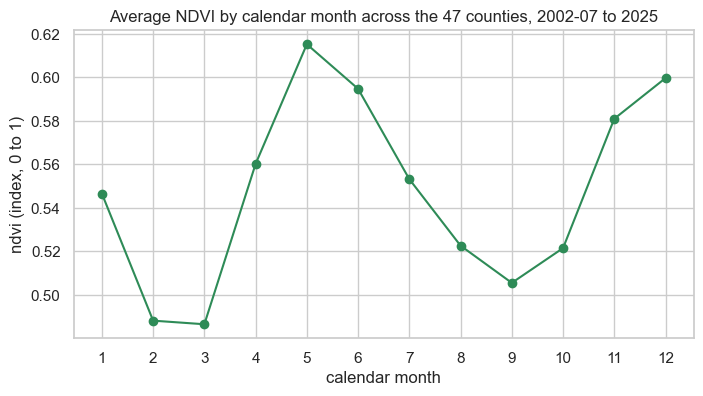

In [36]:
# average NDVI by calendar month, all counties, 2002-07 to 2025
ndvi_by_month = ndvi_features.dropna(subset=["ndvi"]).groupby("month")["ndvi"].mean()
print(ndvi_by_month.round(3).to_dict())
plt.figure(figsize=(8, 4))
plt.plot(ndvi_by_month.index, ndvi_by_month.values, marker="o", color="seagreen")
plt.xticks(range(1, 13))
plt.title("Average NDVI by calendar month across the 47 counties, 2002-07 to 2025")
plt.xlabel("calendar month")
plt.ylabel("ndvi (index, 0 to 1)")
plt.show()

**Observation:** NDVI follows the rain with a delay of about one month. The greenest month is May (0.615), after the April rain peak, and December (0.600) is high after the November peak. The least green months are March (0.487) and February (0.488), after the dry January-February.

## 4. Ocean climate: ONI (El Nino) and DMI (Indian Ocean Dipole)

ONI is the sea-surface temperature anomaly in the central Pacific (above +0.5 is El Nino, below -0.5 is La Nina). DMI is the temperature difference between the western and eastern Indian Ocean (positive means more rain for East Africa). Both are **the same for all 47 counties in a month**, so they are joined on `year` and `month` only.

In [37]:
# load the raw ONI file and give the columns short names
oni = pd.read_csv("../../data/raw/climate_indices/oni.csv")
oni.columns = ["date", "oni"]
print(oni.shape, "| first and last date:", oni["date"].iloc[0], oni["date"].iloc[-1])
print("missing-value code -9999 appears", int((oni["oni"] == -9999).sum()), "times")
oni[oni["oni"] == -9999]

(924, 2) | first and last date: 1950-01-01 2026-12-01
missing-value code -9999 appears 5 times


,date,oni
919,2026-08-01,-9999.0
920,2026-09-01,-9999.0
921,2026-10-01,-9999.0
922,2026-11-01,-9999.0
923,2026-12-01,-9999.0


**Observation:** The ONI file has 924 monthly rows from January 1950 to December 2026. The code -9999 appears 5 times (August to December 2026), months that have not happened yet. Left as numbers they would look like extreme La Nina values.

In [38]:
# replace -9999 with a real missing value and split the date
oni["oni"] = oni["oni"].replace(-9999, np.nan)
oni["year"] = pd.to_datetime(oni["date"]).dt.year
oni["month"] = pd.to_datetime(oni["date"]).dt.month
oni = oni[["year", "month", "oni"]].sort_values(["year", "month"]).reset_index(drop=True)
print("last month with a value:", oni.dropna().iloc[-1][["year", "month"]].astype(int).tolist())
print("months are consecutive:", bool(((oni["year"] * 12 + oni["month"]).diff().dropna() == 1).all()))

last month with a value:

 [2026, 7]
months are consecutive: True


**Observation:** After replacing -9999 with NaN, the last real value is July 2026. Months are consecutive, so shifting by one row is shifting by one month.

**Why ONI is shifted back one month.** NOAA labels each 3-month running mean by its **centre** month. The published ONI for April 2024 is the mean of March, April and May, so it already contains May, the month after April. A model standing in April cannot know May. The published value for March is the mean of February, March and April, which is all known by the end of April. So in the row for month *t* we use the published value of month *t-1*.

In [39]:
# shift ONI back one month (row t carries the published value of t-1)
oni["oni_published"] = oni["oni"]
oni["oni"] = oni["oni_published"].shift(1)
oni[(oni["year"] == 2024) & (oni["month"].isin([2, 3, 4, 5]))]

,year,month,oni,oni_published
889,2024,2,1.92,1.62
890,2024,3,1.62,1.26
891,2024,4,1.26,0.82
892,2024,5,0.82,0.49


**Observation:** In the row for April 2024 the shifted `oni` is 1.26, which is the published March value, while the published April value is 0.82. So the April row only uses information that was already published at the end of March. Every row shows the previous month's published value (the May row has 0.82).

In [40]:
# lags 1 to 3 of the shifted ONI
for k in [1, 2, 3]:
    oni["oni_lag" + str(k)] = oni["oni"].shift(k)
oni[(oni["year"] == 2024) & (oni["month"] == 4)][["year", "month", "oni", "oni_lag1", "oni_lag2", "oni_lag3"]]

,year,month,oni,oni_lag1,oni_lag2,oni_lag3
891,2024,4,1.26,1.62,1.92,2.06


**Observation:** For April 2024, `oni` is 1.26 and its lags are 1.62 (`oni_lag1`), 1.92 (`oni_lag2`) and 2.06 (`oni_lag3`). The El Nino was weakening over these four months (2.06 -> 1.26).

In [41]:
# look at the header of the DMI text file
with open("../../data/raw/climate_indices/dmi_ersstv6.txt", encoding="utf-8", errors="replace") as f:
    header = [next(f).rstrip() for _ in range(14)]
for line in header[5:14]:
    print(repr(line[:80]))

'Climatology : 1991-2020'
''
'WTIO  : SSTA averaged in [50ºE-70ºE, 10ºS-10ºN]'
'SETIO : SSTA averaged in [90ºE-110ºE, 10ºS-0]'
'DMI  = WTIO - SETIO'
''
'  Year   Month     WTIO      SETIO       DMI'
''
'  1950     1      -0.76      -0.99       0.23'


**Observation:** The header says the anomalies use a 1991-2020 climatology and DMI = WTIO - SETIO, where WTIO and SETIO are sea-surface temperature anomalies in the western and south-eastern Indian Ocean. The data starts at January 1950 (WTIO -0.76, SETIO -0.99, DMI 0.23), after 13 header lines that we skip.

In [42]:
# read the DMI table, skipping the 13 header lines
dmi = pd.read_csv("../../data/raw/climate_indices/dmi_ersstv6.txt", sep=r"\s+", skiprows=13, header=None,
                  names=["year", "month", "wtio", "setio", "dmi"], encoding="utf-8", encoding_errors="replace")
dmi = dmi[["year", "month", "dmi"]].astype({"year": int, "month": int})
print(dmi.shape, "| first row:", dmi.iloc[0].tolist(), "| last row:", dmi.iloc[-1].tolist())
print("months are consecutive:", bool(((dmi["year"] * 12 + dmi["month"]).diff().dropna() == 1).all()))
print("missing values:", int(dmi["dmi"].isna().sum()))

(920, 3) | first row: [1950.0, 1.0, 0.23] | last row: [2026.0, 8.0, 0.68]
months are consecutive: True
missing values: 0


**Observation:** The DMI table has 920 rows, from January 1950 to August 2026 (last value 0.68). Months are consecutive and nothing is missing.

**Why DMI is not shifted.** DMI is a plain monthly value (western minus eastern Indian Ocean temperature for that single month). It is not a centred running mean, so the DMI of month *t* only uses month *t* and is complete when the month ends. We still add lags 1 to 3, because the ocean affects East African rainfall with a delay.

In [43]:
# lags 1 to 3 of DMI
for k in [1, 2, 3]:
    dmi["dmi_lag" + str(k)] = dmi["dmi"].shift(k)
dmi[(dmi["year"] == 2024) & (dmi["month"] == 4)]

,year,month,dmi,dmi_lag1,dmi_lag2,dmi_lag3
891,2024,4,0.45,0.41,0.25,0.7


**Observation:** For April 2024, `dmi` is 0.45 with lags 0.41, 0.25 and 0.70. A DMI above about +0.4 is a positive Indian Ocean Dipole, which usually means wetter East Africa.

In [44]:
# join ONI and DMI on year and month and keep 2000-2025
climate_month = oni[["year", "month", "oni", "oni_lag1", "oni_lag2", "oni_lag3"]].merge(dmi, on=["year", "month"], how="inner")
climate_month = climate_month[climate_month["year"].between(2000, 2025)].reset_index(drop=True)
print(climate_month.shape, "| missing values:", int(climate_month.isna().sum().sum()))
print("months:", len(climate_month), "= 26 years x 12")

(312, 10) | missing values: 0
months: 312 = 26 years x 12


**Observation:** The merged ocean table has 312 rows (26 years x 12 months) and no missing values, since ONI is valid until July 2026 and DMI until August 2026.

ONI max and min: 2.75 -1.66 | DMI max and min: 1.17 -0.89


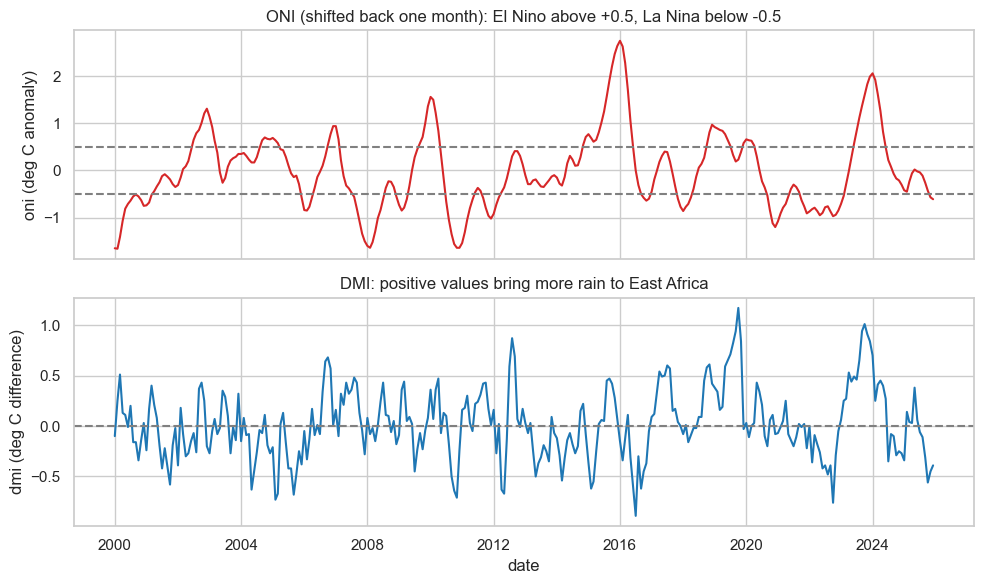

In [45]:
# plot ONI (shifted) and DMI from 2000 to 2025
dates = pd.to_datetime(climate_month["year"].astype(str) + "-" + climate_month["month"].astype(str) + "-01")
print("ONI max and min:", climate_month["oni"].max(), climate_month["oni"].min(), "| DMI max and min:", climate_month["dmi"].max(), climate_month["dmi"].min())
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(dates, climate_month["oni"], color="tab:red")
axes[0].axhline(0.5, color="grey", linestyle="--")
axes[0].axhline(-0.5, color="grey", linestyle="--")
axes[0].set_title("ONI (shifted back one month): El Nino above +0.5, La Nina below -0.5")
axes[0].set_ylabel("oni (deg C anomaly)")
axes[1].plot(dates, climate_month["dmi"], color="tab:blue")
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("DMI: positive values bring more rain to East Africa")
axes[1].set_ylabel("dmi (deg C difference)")
axes[1].set_xlabel("date")
plt.tight_layout()
plt.show()

**Observation:** ONI (shifted) reaches +2.75 in January 2016 (the 2015-16 El Nino) and falls to -1.66 in February 2000 (La Nina). DMI goes from -0.89 (July 2016) to +1.17 (October 2019, the strong positive dipole of 2019). ONI changes slowly over many months, while DMI jumps up and down more quickly.

In [46]:
# attach the same ocean values to all 47 counties
climate_features = grid[["pcode", "year", "month"]].merge(climate_month, on=["year", "month"], how="left")
print(climate_features.shape, "| missing:", int(climate_features.isna().sum().sum()))
print("distinct oni values in Kisumu April 2024 and in Mombasa April 2024:",
      float(climate_features[(climate_features["pcode"] == "KE042") & (climate_features["year"] == 2024) & (climate_features["month"] == 4)]["oni"].iloc[0]),
      float(climate_features[(climate_features["pcode"] == "KE001") & (climate_features["year"] == 2024) & (climate_features["month"] == 4)]["oni"].iloc[0]))

(14664, 11) | missing: 0
distinct oni values in Kisumu April 2024 and in Mombasa April 2024: 1.26 1.26


**Observation:** Kisumu and Mombasa have the same `oni` in April 2024 (1.26), and the table has no missing values. Ocean values do not separate counties, only months: each month's value is repeated 47 times.

In [47]:
# check against the pipeline's data/interim/climate.csv
pipe_clim = pd.read_csv("../../data/interim/climate.csv", dtype={"pcode": str})
both = climate_features.merge(pipe_clim, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
clim_cols = ["oni", "oni_lag1", "oni_lag2", "oni_lag3", "dmi", "dmi_lag1", "dmi_lag2", "dmi_lag3"]
print("rows matched:", len(both))
print("largest difference over the 8 columns:", max(float((both[c] - both[c + "_pipe"]).abs().max()) for c in clim_cols))

rows matched: 14664
largest difference over the 8 columns: 0.0


**Observation:** All 8 ocean columns match the pipeline's `climate.csv` (largest difference 0.0) for all 14,664 rows.

## 5. Put the four parts together and save

In [48]:
# join rainfall, neighbour rain, NDVI and climate onto the grid (row count must stay 14,664)
result = grid[["pcode", "year", "month"]].copy()
for part in [rain_features, neighbour, ndvi_features, climate_features]:
    result = result.merge(part, on=["pcode", "year", "month"], how="left", validate="one_to_one")
    print("rows after merge:", len(result))
print(result.shape)

rows after merge: 14664
rows after merge: 14664
rows after merge: 14664
rows after merge: 14664
(14664, 21)


**Observation:** Each of the four left merges keeps 14,664 rows, so no county-month was lost or duplicated. The result has 21 columns: 3 keys and 18 features.

In [49]:
# missing values per column and save
missing = result.isna().sum()
print(missing[missing > 0].to_dict())
os.makedirs("../../data/interim", exist_ok=True)
result.to_csv("../../data/interim/nb_rain_ndvi_climate.csv", index=False)
print("saved", result.shape, "to data/interim/nb_rain_ndvi_climate.csv")

{'ndvi': 1410, 'ndvi_pct_normal': 1410}


saved (14664, 21) to data/interim/nb_rain_ndvi_climate.csv


**Observation:** Only `ndvi` and `ndvi_pct_normal` have missing values (1,410 each, before July 2002). The file `data/interim/nb_rain_ndvi_climate.csv` has 14,664 rows x 21 columns and is used in notebook 04.

## Summary

- **Rainfall:** province rows dropped (the KE023 level-1 row covers about 173,000 km2 instead of Turkana's 68,111 km2); level-2 areas combined by the n_pixels-weighted mean; dekads summed to months (3 per month checked); lags and the 3-month total computed before trimming to 2000; `rain_pct_normal` uses the 2000-2019 same-month mean.
- **Known limitation:** sub-counties of Kiambu / Murang'a and Kericho / Bomet are filed under the wrong county (Kiambu covers about half of its area, Murang'a about 145%, Kericho about 82%, Bomet about 120%), which also touches `neighbour_rain` of 16 other counties.
- **Neighbour rain:** equal-weight mean of the touching counties, lag 1 computed before trimming. Matches the pipeline exactly.
- **NDVI:** mean (not sum) of 3 dekads; 1,410 blanks before 2002-07 are left blank on purpose.
- **ONI** is shifted back one month so a row never contains the following month; **DMI** is not shifted because it is a single-month value. Both are the same for all counties.
- Every column matches the pipeline's interim files. Result saved as `data/interim/nb_rain_ndvi_climate.csv` (14,664 rows). Next: notebook 03 (soil, runoff, discharge, static features).